In [1]:
#Very first step is to import these modules and libraries into the satprocessing kernel
import numpy as np
import dask as ds
import earthaccess as ea
import xarray as xr
import sys
import matplotlib.pyplot as plt
import requests
import pandas as pd
import PyCO2SYS as pyco2
import cartopy
from shapely.ops import unary_union
import cartopy.feature as cfeature
from datetime import date
from scipy.spatial import KDTree
from datasets import Dataset
print("module import success")

import sys
sys.path.append(r'C:\\Users\\edmund.gable\\Documents\\Hollings_2026\\RESOURCES\\python\\utilities\\bootstrap\\')
print("path import success")

import pprint
from environment import bootstrap_environment  
pprint.pprint(bootstrap_environment(preferred="edmund_gable"))
print("success")

from utilities.bootstrap.environment import bootstrap_environment
env = bootstrap_environment(preferred="edmund.gable")
env
print("utilities import success")

#Before this next step, install the library 'resource': conda install -c conda-forge resource
from utilities import get_dates, get_source_file_dates, find_text
find_text("stats")

from utilities import get_prod_files 
get_prod_files("DO", period="DOY")
#"DOY" is climatological 'day of year
#'W' is climatological weekly files

from pathlib import Path

root = Path(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026")
raw_data = Path(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw_Data")
model_data = Path(r"Z:\\MOM6\Hindcasts\\BTM-O2-REGRID")
processed_data=Path(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison")




c:\Users\edmund.gable\.conda\envs\satprocessing\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


module import success
path import success
⚠ Unrecognized preferred label 'edmund_gable'. Valid options: ['NECMAC04363461.local', 'nefscsatdata', 'guihyde', 'Mac.localdomain', 'gdavis', 'egable']
{'dataset_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/DATASETS'),
 'hostname': 'NECL04363598',
 'lookuptable_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/workflow_resources/lookuptables'),
 'metadata_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/workflow_resources/metadata'),
 'project_root': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/python'),
 'python_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/python'),
 'satlogs_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/logs/satprocessing'),
 'timestamp': datetime.datetime(2026, 6, 29, 10, 21, 49, 800285),
 'utilities_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RE

In [2]:
# 1. Establish the Master Blueprint Grid Layout
dsg = xr.open_dataset(r"Z:\MOM6\Hindcasts\BTM-O2-REGRID\2005\03\CEFI-BTM_O2-HINDCAST-20050321.nc")
ny, nx = len(dsg.lat), len(dsg.lon)
grid_id_matrix = np.array([[f"{y},{x}" for x in range(nx)] for y in range(ny)], dtype=str)
grid_ds = dsg.assign_coords(grid_id=(['lat', 'lon'], grid_id_matrix))


In [3]:

def classify_DO(df, DO_column, status_col, battery_col=None):
    clean_df = df[df[DO_column] > 0].copy()
    classified_df = clean_df.copy()

    classified_df.loc[classified_df[DO_column] >= 3.9, status_col] = 'Low Oxygen'
    classified_df.loc[classified_df[DO_column] > 5.0, status_col] = 'Oxygenated' 
    classified_df.loc[classified_df[DO_column] < 3.9, status_col] = 'Mildly Hypoxic'
    classified_df.loc[classified_df[DO_column] < 2.41, status_col] = 'Hypoxia'
    classified_df.loc[classified_df[DO_column] < 0.2, status_col] = 'Anoxia'
      
    return classified_df
    
def open_file(file):
    ds = xr.open_dataset(file)
    df = ds.to_dataframe().reset_index()
    print("Available flattened columns:", df.columns.to_list())
    return df

def check_units(df, DO_col):
    # If checking pandas dataframe attributes instead of xarray dataset
    print(f"Checking units setup for column: {DO_col}")

In [17]:
def prepare_df(df, DO_col, id_col, obs_depth_col, bottom_depth_col, lat_col, lon_col, time_col, mom6_grid_df, battery_col=None):
    df = df.dropna(subset=[DO_col])

    depth_mismatch = abs(df[obs_depth_col] - df[bottom_depth_col]).astype(float)
    max_mismatch = np.minimum(0.1 * df[bottom_depth_col], 20)
    df_filtered = df[depth_mismatch < max_mismatch].copy()

    df_filtered["matched_time"] = pd.to_datetime(df_filtered[time_col]).dt.normalize() + pd.Timedelta(hours=12)
   
    pt_lats = xr.DataArray(df_filtered[lat_col], dims='points')
    pt_lons = xr.DataArray(df_filtered[lon_col], dims='points')

    nearest_grid = grid_ds.sel(lat=pt_lats, lon=pt_lons, method='nearest')

    df_filtered['matched_lat'] = nearest_grid.lat.values
    df_filtered['matched_lon'] = nearest_grid.lon.values
    df_filtered['grid_id'] = nearest_grid.grid_id.values.astype(str)
    df = df_filtered

    rename_dict = {
        DO_col: "dissolved_oxygen",
        id_col: "id",
        obs_depth_col: "obs_depth",
        bottom_depth_col: "bottom_depth",
        lat_col: "lat",
        lon_col: "lon",
        time_col: "time",
    }
    df = df.rename(columns=rename_dict)
    
    agg_rules = {
        "dissolved_oxygen": "mean",    
        "obs_depth": "mean",           
        "bottom_depth": "mean",        
        "lat": "mean",                 
        "lon": "mean",                 
        "id": "first",                 
        "matched_lat": "first",        
        "matched_lon": "first"         
    }
      
    df = df.groupby(['matched_time', 'grid_id'], as_index=False).agg(agg_rules)
    df = classify_DO(df, 'dissolved_oxygen', 'DO_status', battery_col=battery_col)
    
    requested_columns = [
        "id", "lat", "lon", "obs_depth", "bottom_depth",
        "dissolved_oxygen", "DO_status", "grid_id",
        "matched_time", "matched_lat", "matched_lon"
    ]
    return df[requested_columns]


def prepare_df_no_depth(df, DO_col, id_col, lat_col, lon_col, time_col, mom6_grid_df, battery_col=None):
    df_filtered = df.dropna(subset=[DO_col]).copy()

    if battery_col is not None and battery_col in df_filtered.columns:
        df_filtered = df_filtered[df_filtered[battery_col] >= 50]
        
    df_filtered = df_filtered.reset_index(drop=True)
    df_filtered["matched_time"] = pd.to_datetime(df_filtered[time_col]).dt.normalize() + pd.Timedelta(hours=12)
     
    pt_lats = xr.DataArray(df_filtered[lat_col], dims='points')
    pt_lons = xr.DataArray(df_filtered[lon_col], dims='points')

    nearest_grid = grid_ds.sel(lat=pt_lats, lon=pt_lons, method='nearest')

    df_filtered['matched_lat'] = nearest_grid.lat.values
    df_filtered['matched_lon'] = nearest_grid.lon.values
    raw_ids = nearest_grid.grid_id.values.astype(str)
    
    # 2. Strip any negative signs and ensure a clean space after the separator
    clean_ids = [str(rid).replace('-', '') for rid in raw_ids]
    
    # 3. Save it to the dataframe
    df_filtered['grid_id'] = clean_ids
    # FIX: Cleaned up the assignment typo and converted cleanly to text string arrays
    df_filtered['grid_id'] = nearest_grid.grid_id.values.astype(str)

    rename_dict = {
        DO_col: "dissolved_oxygen",
        id_col: "id",
        lat_col: "lat",
        lon_col: "lon",
        time_col: "time",
    }
    df_mapped = df_filtered.rename(columns=rename_dict)
    
    agg_rules = {
        "dissolved_oxygen": "mean",     
        "lat": "mean",                  
        "lon": "mean",                  
        "id": "first",                  
        "matched_lat": "first",         
        "matched_lon": "first"          
    }
    
    # FIX: added as_index=False so pandas doesn't convert grid_id into a MultiIndex row layout
    df_agg = df_mapped.groupby(['matched_time', 'grid_id'], as_index=False).agg(agg_rules)
    df_classified = classify_DO(df_agg, 'dissolved_oxygen', 'DO_status', battery_col=battery_col)
    
    requested_columns = [
        "id", "lat", "lon", "dissolved_oxygen", "DO_status",  
        "grid_id", "matched_time", "matched_lat", "matched_lon"
    ]
    return df_classified[requested_columns]

#Use this function to match mom6 data to observational data 
def load_matching_mom6_data(df, model_data):

    #load in a dataframe list to fill
    df_list = []

    # Get the list of unique datetimes from observational data
    unique_dates = pd.to_datetime(df['matched_time']).dt.normalize().unique()

    print(f"Found {len(unique_dates)} unique dates to query")

    #set the date structure
    for date in unique_dates:
        year = str(date.year)
        month = f"{date.month:02d}"
        day = f"{date.day:02d}"
        
        # Match the exact filename structure
        file_name = f"CEFI-BTM_O2-HINDCAST-{year}{month}{day}.nc"
        target_file_path = model_data / year / month / file_name
        
        # Filter the cruise dataframe down to just the points needed for this specific day
        current_date_str = f"{year}-{month}-{day}"
        df_day = df[pd.to_datetime(df['matched_time']).dt.normalize() == date]
        
        # Check if the file exists before attempting to open it
        if target_file_path.exists():
            print(f"Extracting data for {current_date_str}...")
            
            # Open the dataset
            ds = xr.open_dataset(target_file_path)
            
            # Extract ONLY the bottom oxygen variable
            o2_slice = ds['btm_o2'] 
            
            #  Target only the specific grid IDs present on this day ---
            for _, row in df_day.iterrows():
              try:
                    # Use coordinate matching (.sel) instead of positional indexing (.isel)
                    # This searches the grid using the target latitude and longitude directly
                    model_val = o2_slice.sel(
                        lat=row['matched_lat'], 
                        lon=row['matched_lon'], 
                        method='nearest'
                    ).values
                    
                    #  convert the resulting numpy array/scalar into a standard float
                    btm_o2_val = float(np.atleast_1d(model_val)[0])
              except Exception as e:
                    print(f" Lookup failed for Lat {row['matched_lat']}, Lon {row['matched_lon']}: {e}")
                    btm_o2_val = np.nan

                
                # Build a single clean row combining the cruise data with the model value
              matched_row = row.to_dict()
              matched_row['btm_o2'] = btm_o2_val
              df_list.append(matched_row)
            
            # Close the dataset file connection 
            ds.close()
        else:
            print(f"⚠️ Model file not found for {year}-{month}-{day} at: {target_file_path}")
            # If the file is missing, still retain the cruise data rows but fill model data with NaN
            for _, row in df_day.iterrows():
                matched_row = row.to_dict()
                matched_row['btm_o2'] = np.nan
                df_list.append(matched_row)

    # 4. Convert all individual rows into one single, master DataFrame
    if df_list:
        final_model_df = pd.DataFrame(df_list)
        return final_model_df
    else:
        print("No matching model files were found or loaded.")
        return pd.DataFrame() # Return empty dataframe as fallback
def delta_difference(df):
    # 1. Only calculate where model values exist
    df = df.dropna(subset=['closest_model_val']).copy()
    
    # 2. Calculate point-by-point delta difference
    df['delta_difference_point'] = df['exact_model_val'] - df['dissolved_oxygen']
    df['delta_difference_grid'] = df['closest_model_val'] - df['dissolved_oxygen']
    print(f"Mean of delta difference between model 3x3x3 grid data and observational data is: {np.nanmean(df['delta_difference_grid']):4f}")
    print(f"Mean of delta difference between model exact grid data and observational data is: {np.nanmean(df['delta_difference_point']):4f}")
    # 3. Calculate Global Dataset RMSE
    # RMSE is the square root of the mean of squared differences between model and observations
    global_rmse_grid = np.sqrt(np.nanmean(df['delta_difference_grid'] ** 2))
    print(f"Global RMSE (3x3x3 grid vs obs) between model and observations is: {global_rmse_grid:.4f}")
    
# Exact Match RMSE (Slices down to only where valid exact pairs exist)
    valid_exact = df.dropna(subset=['delta_difference_point'])
    global_rmse_exact = np.sqrt((valid_exact['delta_difference_point'] ** 2).mean())
    print(f"Global RMSE (Exact point vs Obs): {global_rmse_exact:.4f}")
    print(f"-> Calculated using {len(valid_exact)} valid exact points (out of {len(df)} total pairs).")

    # 4. Calculate Local Z-score (point relative to its 3x3x3 grid)
    # Note: Added 1e-9 to prevent division-by-zero if a cube std is 0 
    df['local_z_score'] = (df['cube_mean'] - df['dissolved_oxygen']) / (df['cube_std'] + 1e-9)
    
    # 5. Calculate Global Statistics using Grand Variance formulas (assuming N=27 for each grid)
    global_mean = df['cube_mean'].mean()
    obs_mean=df['dissolved_oxygen'].mean()
    
    # Combined variance formula: mean of variances + variance of means
    mean_of_variance=(df['cube_std']**2).mean()
    variance_of_means=df['cube_mean'].var()

    global_variance = mean_of_variance + variance_of_means
    global_std = np.sqrt(global_variance)
    
    print(f"Calculated Observational Mean: {obs_mean:.4f}")
    print(f"Calculated Model Global Mean: {global_mean:.4f}")
    print(f"Calculated Global Std Dev: {global_std:.4f}")
    over_est_pct=(df['delta_difference_grid']>0).mean()*100
    under_est_pct=(df['delta_difference_grid']<0).mean()*100
    print(f"Model grid overestimates the data {over_est_pct} percent of the time")
    print(f"Model grid underestimates the data {under_est_pct} percent of the time")
    avg_overestimation = df[df['delta_difference_grid'] > 0]['delta_difference_grid'].mean()
    avg_underestimation = df[df['delta_difference_grid'] < 0]['delta_difference_grid'].mean()

    print(f"When overestimating, the average excess oxygen is: {avg_overestimation:.4f}")
    print(f"When underestimating, the average deficit oxygen is: {avg_underestimation:.4f}")

    # Calculate the standard deviation of your real-world observations
    obs_std = df['dissolved_oxygen'].std()

    print(f"Real-World Observational STD: {obs_std:.4f}")
    print(f"Model Global STD: {global_std:.4f}")

# Compare them
    std_ratio = global_std / obs_std
    print(f"Model-to-Observation Variance Ratio: {std_ratio:.2f}")
    print(f"Model RSR: ({global_rmse_grid/obs_std})")
    
    # 6. Calculate Global Z-score for each observational point
    df['global_z_score'] = (df['dissolved_oxygen'] - global_mean) / global_std


    # 1. Define your subsets (Stressed = Anything that is NOT 'Oxygenated')
    stressed_obs = df[df['DO_status'] != 'Oxygenated']
    stressed_mod = df[df['model_DO_status'] != 'Oxygenated']

    if len(stressed_obs) > 0:
        # --- RAW COUNTS ---
        # Total Stressed Predictions by the model
        total_predicted_stress = len(stressed_mod)
        
        # True Positives: Model predicted stress, and the observation WAS ALSO stressed 
        # (Regardless of whether they match exactly, e.g., Model='Hypoxic', Obs='Anoxic' is a hit)
        true_positives = (stressed_mod['DO_status'] != 'Oxygenated').sum()
        
        # False Positives: Model predicted stress, but it was actually 'Oxygenated'
        false_positives = (stressed_mod['DO_status'] == 'Oxygenated').sum()
        
        # False Negatives: Observation showed stress, but model missed it (predicted 'Oxygenated')
        false_negatives = (stressed_obs['model_DO_status'] == 'Oxygenated').sum()
        
        # --- PERCENTAGES & METRICS ---
        mod_len = total_predicted_stress if total_predicted_stress > 0 else 1
        
        # General Stress Precision: Out of all times the model predicted stress, how often was there ACTUALLY stress?
        stress_precision = (true_positives / mod_len) * 100
        
        # False Positive Rate: Out of all times the model predicted stress, how often was it completely fine?
        fpp = (false_positives / mod_len) * 100
        
        # False Negative Rate: Out of all actual stressed events, how many did the model completely miss?
        fnp = (false_negatives / len(stressed_obs)) * 100
        
        # Recall / Sensitivity: Out of all actual stressed events, how many did the model flag as stressed?
        stress_recall = (true_positives / len(stressed_obs)) * 100
        
        # --- PRINT STATS ---
        print(f"\n===========================================================")
        print(f"GENERAL STRESS DETECTION METRICS (Binary: Stress vs No Stress)")
        print(f"===========================================================")
        print(f"Total observations showing stressed conditions: {len(stressed_obs)}")
        print(f"Total model outputs showing stressed conditions: {total_predicted_stress}")
        print(f'False Positives: Of the {total_predicted_stress} times the model predicted stress, {fpp:.2f}% were false alarms (actually oxygenated)')
        print(f'False Negatives: Of the {len(stressed_obs)} times the observations detected stress, {fnp:.2f}% were completely missed (predicted oxygenated)')
        print(f'Stress Precision: Of the {total_predicted_stress} times the model predicted stress, {stress_precision:.2f}% correctly co-occurred with an observed stress event')
        print(f"Stress Recall (Capture Rate): Of the {len(stressed_obs)} actual stress events, the model flagged {stress_recall:.2f}% of them")
    return df


In [69]:
def load_3x3x3_MOM6(df, model_data, mom6_var='btm_o2'):
    model_data = Path(model_data)
    df_list = []

    df = df.copy()
    df['matched_time'] = pd.to_datetime(df['matched_time'])
    unique_dates = df['matched_time'].dt.normalize().unique()

    print(f"Found {len(unique_dates)} unique dates to query.")

    for center_date in unique_dates:
        t_minus = center_date - pd.Timedelta(days=1)
        t_plus  = center_date + pd.Timedelta(days=1)
        target_days = [t_minus, center_date, t_plus]
        
        daily_slices = []

        for d in target_days:
            year = str(d.year)
            month = f"{d.month:02d}"
            day = f"{d.day:02d}"
            
            file_name = f"CEFI-BTM_O2-HINDCAST-{year}{month}{day}.nc"
            target_file_path = model_data / year / month / file_name

            if target_file_path.exists():
                ds = xr.open_dataset(target_file_path)
                o2_converted = ds[mom6_var] * 31998.8 * 1.025
                daily_slices.append(o2_converted)
                ds.close()
                    
        if not daily_slices:
            continue

        print(f"Extracting 3x3x3 space-time matrix for {center_date.strftime('%Y-%m-%d')}...")
        df_day = df[df['matched_time'].dt.normalize() == center_date]

        ds_window = xr.concat(daily_slices, dim='time')
        
        # FIX: Align the daily window map directly to the master template coordinates
        ds_window = ds_window.assign_coords(grid_id=(['lat', 'lon'], grid_ds.grid_id.values))
        ds_window['grid_id'] = ds_window['grid_id'].astype(str)

        lat_arr = ds_window.lat.values
        lon_arr = ds_window.lon.values

        for idx, row in df_day.iterrows():
            lat_idx = int(np.argmin(np.abs(lat_arr - row['lat'])))
            lon_idx = int(np.argmin(np.abs(lon_arr - row['lon'])))
            
            lat_slice = slice(max(0, lat_idx - 1), lat_idx + 2)
            lon_slice = slice(max(0, lon_idx - 1), lon_idx + 2)
            
            cube_3x3x3 = ds_window.isel(lat=lat_slice, lon=lon_slice)
            o2_cube = cube_3x3x3.values 
            
            if np.all(np.isnan(o2_cube)):
                continue

            #calculate the mean, std, min and max of the cube values
            mean_o2 = float(np.nanmean(o2_cube))
            std_o2  = float(np.nanstd(o2_cube))
            min_o2  = float(np.nanmin(o2_cube))
            max_o2  = float(np.nanmax(o2_cube))

            abs_diff = np.abs(o2_cube - row['dissolved_oxygen'])
            flat_idx = np.nanargmin(abs_diff) 
            grid_t, grid_y, grid_x = np.unravel_index(flat_idx, o2_cube.shape)

            closest_val  = float(o2_cube[grid_t, grid_y, grid_x])
            closest_lat  = float(cube_3x3x3.lat.values[grid_y])
            closest_lon  = float(cube_3x3x3.lon.values[grid_x])
            closest_time = pd.Timestamp(cube_3x3x3.time.values[grid_t])

            #  Safely retrieve the true string index coordinates without negative offsets
            if 'grid_id' in cube_3x3x3.coords:
                # 1. Grab the raw string value and strip any minus signs
                text = str(cube_3x3x3.grid_id.values[grid_y, grid_x]).replace('-', '')
                
                # 2. Split normally (Y first, then X) to match your grid_id layout
                sep = ';' if ';' in text else ','
                y_val, x_val = text.split(sep)
                
                # 3. Wrap it in parentheses with the clean space
                closest_grid_id = f"({y_val.strip()}{sep} {x_val.strip()})"
            else:
                closest_grid_id = f"({closest_lat}, {closest_lon})"

            matched_row = row.to_dict()
            matched_row.update({
                "cube_mean": mean_o2,
                "cube_std": std_o2,
                "cube_min": min_o2,
                "cube_max": max_o2,
                "closest_model_val": closest_val,
                "closest_grid_id": closest_grid_id,
                "closest_lat": closest_lat,
                "closest_lon": closest_lon,
                "closest_time": closest_time
            })
            df_list.append(matched_row)

    return pd.DataFrame(df_list).reset_index(drop=True)

In [5]:
#do both grid and exact at once

def load_combined_mom6_data(df, model_data, mom6_var='btm_o2', grid_ds=None):
    model_data = Path(model_data)
    df_list = []
    
    df = df.copy()
    df['matched_time'] = pd.to_datetime(df['matched_time'])
    unique_dates = df['matched_time'].dt.normalize().unique()
    
    print(f"Processing {len(unique_dates)} unique dates...")
    
    for center_date in unique_dates:
        # 1. Load the 3-day window around the center date
        target_days = [center_date - pd.Timedelta(days=1), center_date, center_date + pd.Timedelta(days=1)]
        daily_slices = []
        
        for d in target_days:
            file_name = f"CEFI-BTM_O2-HINDCAST-{d.year}{d.month:02d}{d.day:02d}.nc"
            target_file_path = model_data / f"{d.year}" / f"{d.month:02d}" / file_name
            
            if target_file_path.exists():
                with xr.open_dataset(target_file_path) as ds:
                    # Apply unit conversion uniformly if needed
                    o2_converted = ds[mom6_var] * 31998.8 * 1.025
                    daily_slices.append(o2_converted.load()) # Load to memory for performance
                    
        if not daily_slices:
            continue
            
        ds_window = xr.concat(daily_slices, dim='time')
        if grid_ds is not None:
            ds_window = ds_window.assign_coords(grid_id=(['lat', 'lon'], grid_ds.grid_id.values))
            ds_window['grid_id'] = ds_window['grid_id'].astype(str)
            
        lat_arr, lon_arr = ds_window.lat.values, ds_window.lon.values
        df_day = df[df['matched_time'].dt.normalize() == center_date]
        
        # 2. Extract space-time metrics for each observation point on this day
        for idx, row in df_day.iterrows():
            # Find closest center indices
            lat_idx = int(np.argmin(np.abs(lat_arr - row['lat'])))
            lon_idx = int(np.argmin(np.abs(lon_arr - row['lon'])))
            
            # Slice out the 3x3 horizontal window
            lat_slice = slice(max(0, lat_idx - 1), lat_idx + 2)
            lon_slice = slice(max(0, lon_idx - 1), lon_idx + 2)
            cube_3x3x3 = ds_window.isel(lat=lat_slice, lon=lon_slice)
            o2_cube = cube_3x3x3.values 
            
            if np.all(np.isnan(o2_cube)):
                continue
                
            # --- EXACT SPATIOTEMPORAL MATCH ---
            # Index exact center (Time=center_date, and center cell of our slice)
            time_deltas = np.abs(pd.to_datetime(cube_3x3x3.time.values) - center_date)
            t_exact_idx = int(np.argmin(time_deltas))
           # t_exact_idx = np.where(pd.to_datetime(cube_3x3x3.time.values).date == center_date.date())[0][0]
            y_exact_idx = int(np.argmin(np.abs(cube_3x3x3.lat.values - row['lat'])))
            x_exact_idx = int(np.argmin(np.abs(cube_3x3x3.lon.values - row['lon'])))
            exact_match_val = float(o2_cube[t_exact_idx, y_exact_idx, x_exact_idx])

            # --- CLOSEST 3x3x3 NEIGHBOR MATCH ---
            abs_diff = np.abs(o2_cube - row['dissolved_oxygen'])
            flat_idx = np.nanargmin(abs_diff) 
            grid_t, grid_y, grid_x = np.unravel_index(flat_idx, o2_cube.shape)
            
            closest_val = float(o2_cube[grid_t, grid_y, grid_x])
            closest_lat = float(cube_3x3x3.lat.values[grid_y])
            closest_lon = float(cube_3x3x3.lon.values[grid_x])
            closest_time = pd.Timestamp(cube_3x3x3.time.values[grid_t])
            
            # Extract Grid ID
            if 'grid_id' in cube_3x3x3.coords:
                text = str(cube_3x3x3.grid_id.values[grid_y, grid_x]).replace('-', '')
                sep = ';' if ';' in text else ','
                y_val, x_val = text.split(sep)
                closest_grid_id = f"({y_val.strip()}{sep} {x_val.strip()})"
            else:
                closest_grid_id = f"({closest_lat}, {closest_lon})"
                
            # --- MERGE INTO DATA DICTIONARY ---
            matched_row = row.to_dict()
            matched_row.update({
                "exact_model_val": exact_match_val,
                "cube_mean": float(np.nanmean(o2_cube)),
                "cube_std": float(np.nanstd(o2_cube)),
                "cube_min": float(np.nanmin(o2_cube)),
                "cube_max": float(np.nanmax(o2_cube)),
                "closest_model_val": closest_val,
                "closest_grid_id": closest_grid_id,
                "closest_lat": closest_lat,
                "closest_lon": closest_lon,
                "closest_time": closest_time
            })
            df_list.append(matched_row)
            
    return pd.DataFrame(df_list).reset_index(drop=True)

In [6]:

# 2. Extract Observational Fields
file = r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw_Data\eMOLT\eMOLT_2000_2026.nc"
df = open_file(file)
check_units(df, 'DO')

# 3. Read Extent Settings
mom6_grid_df = pd.read_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Index\MOM6_Grid_Extent.csv")

# 4. Generate the Prepared Dataframe
dfp = prepare_df_no_depth(df, 'DO', 'tow_id', 'latitude', 'longitude', 'time', mom6_grid_df, 'water_detect_perc')


#dfp.to_csv(processed_data /  "eMOLT_MOM6_grid_matched.csv")

print("Export Complete! Data successfully compiled.")

Available flattened columns: ['row', 'tow_id', 'time', 'latitude', 'longitude', 'temperature', 'DO', 'DO_percentage', 'water_detect_perc', 'sensor_type']
Checking units setup for column: DO
Export Complete! Data successfully compiled.


In [41]:
# Load your observational csv
dfp = pd.read_csv(processed_data / "eMOLT_MOM6_grid_matched.csv")

# Run the query function
#eMOLT = load_3x3x3_MOM6(dfp, model_data, mom6_var='btm_o2')
eMOLT=load_combined_mom6_data(dfp, model_data, mom6_var='btm_o2', grid_ds=grid_ds)


Processing 692 unique dates...


In [52]:
final=delta_difference(eMOLT)
final.to_csv(processed_data  / 'eMOLT_MOM6_3x3x3_comparison.csv')
final

Mean of delta difference between model 3x3x3 grid data and observational data is: 2.371695
Mean of delta difference between model exact grid data and observational data is: 2.708532
Global RMSE (3x3x3 grid vs obs) between model and observations is: 2.8602
Global RMSE (Exact point vs Obs): 3.1046
-> Calculated using 293 valid exact points (out of 369 total pairs).
Calculated Observational Mean: 6.2342
Calculated Model Global Mean: 8.7650
Calculated Global Std Dev: 0.6551
Model grid overestimates the data 90.2439024390244 percent of the time
Model grid underestimates the data 9.75609756097561 percent of the time
When overestimating, the average excess oxygen is: 2.7715
When underestimating, the average deficit oxygen is: -1.3261


,Unnamed: 0,id,lat,lon,dissolved_oxygen,DO_status,grid_id,matched_time,matched_lat,matched_lon,...,cube_max,closest_model_val,closest_grid_id,closest_lat,closest_lon,closest_time,delta_difference_point,delta_difference_grid,local_z_score,global_z_score
0,0,4497.0,41.771200,-70.50370,6.676296,Oxygenated,"307,148",2023-07-31 12:00:00,41.786113,-70.528487,...,9.606815,9.563205,"(308, 149)",41.848851,-70.447812,2023-07-31 12:00:00,NaN,2.886909,162.859321,-3.188204
1,1,4316.0,41.831300,-70.45170,6.770303,Oxygenated,"308,149",2023-07-31 12:00:00,41.848851,-70.447812,...,9.797547,9.484906,"(308, 150)",41.848851,-70.367136,2023-07-31 12:00:00,2.792902,2.714603,24.360097,-3.044715
2,2,4361.0,41.850395,-70.37824,5.688809,Oxygenated,"308,150",2023-07-31 12:00:00,41.848851,-70.367136,...,9.797547,9.484906,"(308, 150)",41.848851,-70.367136,2023-07-31 12:00:00,3.796097,3.796097,33.573511,-4.695477
3,3,4497.0,41.771200,-70.50370,6.307500,Oxygenated,"307,148",2023-08-01 12:00:00,41.786113,-70.528487,...,9.593822,9.563205,"(308, 149)",41.848851,-70.447812,2023-07-31 12:00:00,NaN,3.255704,259.341572,-3.751124
4,4,4316.0,41.831300,-70.45170,6.312084,Oxygenated,"308,149",2023-08-01 12:00:00,41.848851,-70.447812,...,9.795568,9.484379,"(308, 150)",41.848851,-70.367136,2023-08-02 12:00:00,3.270079,3.172295,26.539787,-3.744128
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
364,367,4358.0,41.825100,-70.44100,11.482500,Oxygenated,"308,149",2023-11-11 12:00:00,41.848851,-70.447812,...,8.220432,8.220432,"(308, 150)",41.848851,-70.367136,2023-11-12 12:00:00,-3.468020,-3.262068,-36.053726,4.147854
365,368,4397.0,41.850550,-70.40325,9.378646,Oxygenated,"308,150",2023-11-11 12:00:00,41.848851,-70.367136,...,8.579047,8.579047,"(308, 151)",41.848851,-70.286460,2023-11-12 12:00:00,-1.419890,-0.799599,-7.528834,0.936589
366,369,4397.0,41.850550,-70.40325,10.627708,Oxygenated,"308,150",2023-11-12 12:00:00,41.848851,-70.367136,...,8.612222,8.612222,"(308, 151)",41.848851,-70.286460,2023-11-13 12:00:00,-2.407276,-2.015486,-11.294403,2.843123
367,370,4397.0,41.850628,-70.40295,9.980397,Oxygenated,"308,150",2023-11-13 12:00:00,41.848851,-70.367136,...,8.634256,8.634256,"(308, 151)",41.848851,-70.286460,2023-11-14 12:00:00,-1.540164,-1.346141,-7.271055,1.855085


Combining ECOMON and Fishbot datasets together then running 

In [59]:
mom6_grid_df = pd.read_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Index\MOM6_Grid_Extent.csv")

Fishbot=pd.read_csv(r'c:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\Fishbot_removed_ECOMON.csv')
ECOMON=open_file(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw_Data\Hydrographic_Monitoring\errdap_search.nc")
Fishbot['bottom_depth']=Fishbot['depth']
Fishbot['cruise_id']=Fishbot['data_provider']
Fishbot.drop(columns=['data_provider'], inplace=True)
ECOMON['time'] = pd.to_datetime(ECOMON['UTC_DATETIME'], errors='coerce')
ECOMON.drop(columns=['UTC_DATETIME'], inplace=True)
#print(Fishbot.columns.to_list())
ECOMON=classify_DO(ECOMON, 'dissolved_oxygen', 'DO_status')
merged_df = pd.concat([Fishbot, ECOMON], ignore_index=True)
print(merged_df.columns.to_list())


#dfp=prepare_df(merged_df, 'dissolved_oxygen', 'cruise_id', 'depth', 'bottom_depth', 'latitude', 'longitude', 'time', mom6_grid_df)
#dfp.to_csv(processed_data / 'READ_ME.csv')


Available flattened columns: ['row', 'UTC_DATETIME', 'latitude', 'longitude', 'depth', 'dissolved_oxygen', 'cruise_id', 'purpose_code', 'bottom_depth', 'GEAR_TYPE']
['Unnamed: 0', 'row', 'time', 'temperature', 'dissolved_oxygen', 'dissolved_oxygen_min', 'dissolved_oxygen_max', 'dissolved_oxygen_std', 'salinity', 'grid_id', 'stat_area', 'fishery_dependent', 'depth', 'latitude', 'longitude', 'DO_status', 'bottom_depth', 'cruise_id', 'purpose_code', 'GEAR_TYPE']


In [ ]:
merged_df['time'] = pd.to_datetime(merged_df['time'], errors='coerce')

# 2. Drop rows where time couldn't be parsed (optional, but highly recommended)
merged_df = merged_df.dropna(subset=['time'])

# 3. Now the .dt accessor will work perfectly
merged_df['time'] = merged_df['time'].dt.normalize() + pd.Timedelta(hours=12)
dfp=prepare_df(merged_df, 'dissolved_oxygen', 'cruise_id', 'depth', 'bottom_depth', 'latitude', 'longitude', 'time', mom6_grid_df)
dfp.to_csv(processed_data /  "Concat_MOM6_grid_matched.csv")
dfp


In [71]:
CONCAT=pd.read_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\Concat_MOM6_grid_matched.csv")
dfp=CONCAT[CONCAT['id']!='HB2101']
CONCAT=load_combined_mom6_data(dfp, model_data, mom6_var='btm_o2', grid_ds=grid_ds)
CONCAT.to_csv(processed_data / 'CONCAT_MOM6_3x3x3_prepped.csv')

Processing 3940 unique dates...


In [ ]:
CONCAT=pd.read_csv(processed_data / 'CONCAT_MOM6_3x3x3_prepped.csv')

CONCAT=classify_DO(CONCAT, 'dissolved_oxygen', 'model_DO_status')

final=classify_DO(CONCAT, 'closest_model_val', 'model_DO_status')
final= delta_difference(final)
final.to_csv(processed_data / 'CONCAT_MOM6_3x3x3_comparison.csv')


Mean of delta difference between model 3x3x3 grid data and observational data is: 0.205094
Mean of delta difference between model exact grid data and observational data is: 0.194885
Global RMSE (3x3x3 grid vs obs) between model and observations is: 1.1834
Global RMSE (Exact point vs Obs): 1.5118
-> Calculated using 18118 valid exact points (out of 18350 total pairs).
Calculated Observational Mean: 6.8358
Calculated Model Global Mean: 7.0744
Calculated Global Std Dev: 1.5117
Model grid overestimates the data 56.27792915531336 percent of the time
Model grid underestimates the data 43.72207084468665 percent of the time
When overestimating, the average excess oxygen is: 0.8575
When underestimating, the average deficit oxygen is: -0.6346
Real-World Observational STD: 1.6542
Model Global STD: 1.5117
Model-to-Observation Variance Ratio: 0.91
Model RSR: (0.7153985573818884)

GENERAL STRESS DETECTION METRICS (Binary: Stress vs No Stress)
Total observations showing stressed conditions: 2880
Tota

In [25]:
# 1. Load the data
CONCAT = pd.read_csv(processed_data / 'CONCAT_MOM6_3x3x3_prepped.csv')

# 2. Identify all rows where the 'id' column contains 'glider'
# (Switched 'df' to 'CONCAT' so it matches your loaded DataFrame)
glider_mask = CONCAT['id'].str.contains('glider', case=False, na=False)

# 3. Apply the mL/L to mg/L conversion only to the gliders in the DO column
CONCAT.loc[glider_mask, 'dissolved_oxygen'] = CONCAT.loc[glider_mask, 'dissolved_oxygen'] * 1.42903

# 4. Recalculate your statuses using the newly converted oxygen values
# First, classify the real-world observations ('dissolved_oxygen')
# (Make sure the 3rd argument is 'DO_status' so it maps to your observation status!)
CONCAT = classify_DO(CONCAT, 'dissolved_oxygen', 'DO_status')

# Next, classify the exact point model predictions ('closest_model_val')
CONCAT = classify_DO(CONCAT, 'closest_model_val', 'model_DO_status')

# 5. Run your delta calculations and export
final = delta_difference(CONCAT)
final.to_csv(processed_data / 'CONCAT_MOM6_3x3x3_comparison_glider_converted.csv', index=False)

print("Conversion complete! Data saved to CSV.")

Mean of delta difference between model 3x3x3 grid data and observational data is: -1.411928
Mean of delta difference between model exact grid data and observational data is: -1.436480
Global RMSE (3x3x3 grid vs obs) between model and observations is: 2.2621
Global RMSE (Exact point vs Obs): 2.3660
-> Calculated using 18118 valid exact points (out of 18350 total pairs).
Calculated Observational Mean: 8.4528
Calculated Model Global Mean: 7.0744
Calculated Global Std Dev: 1.5117
Model grid overestimates the data 22.09809264305177 percent of the time
Model grid underestimates the data 77.90190735694823 percent of the time
When overestimating, the average excess oxygen is: 0.9352
When underestimating, the average deficit oxygen is: -2.0777
Real-World Observational STD: 2.3251
Model Global STD: 1.5117
Model-to-Observation Variance Ratio: 0.65
Model RSR: (0.9728871378553047)

GENERAL STRESS DETECTION METRICS (Binary: Stress vs No Stress)
Total observations showing stressed conditions: 604
Tot

In [20]:
ds=xr.open_dataset(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw_Data\Fishbot\ondeckdata_erddap6.nc")
ds

<xarray.Dataset> Size: 18MB
Dimensions:               (row: 222021)
Dimensions without coordinates: row
Data variables: (12/14)
    time                  (row) datetime64[ns] 2MB ...
    temperature           (row) float32 888kB ...
    dissolved_oxygen      (row) float32 888kB ...
    dissolved_oxygen_min  (row) float32 888kB ...
    dissolved_oxygen_max  (row) float32 888kB ...
    dissolved_oxygen_std  (row) float32 888kB ...
    ...                    ...
    grid_id               (row) float64 2MB ...
    stat_area             (row) float64 2MB ...
    fishery_dependent     (row) float64 2MB ...
    depth                 (row) float64 2MB ...
    latitude              (row) float32 888kB ...
    longitude             (row) float32 888kB ...
Attributes: (12/36)
    cdm_data_type:                 Point
    Conventions:                   COARDS, CF-1.10, ACDD-1.3
    creator_name:                  CFRF | NOAA
    creator_type:                  institution
    creator_url:                   https://github.com/CommercialFisheriesRese...
    description:                   Gridded daily observations of demersal oce...
    ...                            ...
    summary:                       Fishing Industry Shared Bottom Oceanograph...
    time_coverage_end:             2026-05-31T00:00:00Z
    time_coverage_start:           2000-01-15T00:00:00Z
    title:                         Hydrographic | CFRF, NEFSC, GOMLF | Fishin...
    version:                       1.1
    Westernmost_Easting:           -77.03396

For ECOMON

In [8]:

# 1. Extract Observational Fields
file = r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw_Data\Hydrographic_Monitoring\errdap_search.nc"
df = open_file(file)
check_units(df, 'dissolved_oxygen')

# 3. Read Extent Settings
mom6_grid_df = pd.read_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Index\MOM6_Grid_Extent.csv")

# 4. Generate the Prepared Dataframe
dfp = prepare_df(df, 'dissolved_oxygen', 'cruise_id', 'depth', 'bottom_depth', 'latitude', 'longitude', 'UTC_DATETIME', mom6_grid_df)


dfp.to_csv(processed_data /  "ECOMON_MOM6_grid_matched.csv")

print("Export Complete! Data successfully compiled.")

Available flattened columns: ['row', 'UTC_DATETIME', 'latitude', 'longitude', 'depth', 'dissolved_oxygen', 'cruise_id', 'purpose_code', 'bottom_depth', 'GEAR_TYPE']
Checking units setup for column: dissolved_oxygen
Export Complete! Data successfully compiled.


In [9]:
ECOMON=load_combined_mom6_data(dfp, model_data, mom6_var='btm_o2', grid_ds=grid_ds)
ECOMON.to_csv(processed_data / 'ECOMON_MOM6_3x3x3_prepped.csv')

Processing 1258 unique dates...


In [19]:
df=pd.read_csv(processed_data / 'ECOMON_MOM6_3x3x3_prepped.csv')
df=df[df['id']!='HB2101'] #removed this cruise because the oxygen detector malfunctioned
final=classify_DO(df, 'closest_model_val', 'model_DO_status', battery_col=None)
print(final.columns.to_list())
final= delta_difference(final)


['Unnamed: 0', 'id', 'lat', 'lon', 'obs_depth', 'bottom_depth', 'dissolved_oxygen', 'DO_status', 'grid_id', 'matched_time', 'matched_lat', 'matched_lon', 'exact_model_val', 'cube_mean', 'cube_std', 'cube_min', 'cube_max', 'closest_model_val', 'closest_grid_id', 'closest_lat', 'closest_lon', 'closest_time', 'model_DO_status']
Mean of delta difference between model 3x3x3 grid data and observational data is: 0.372079
Mean of delta difference between model exact grid data and observational data is: 0.417980
Global RMSE (3x3x3 grid vs obs) between model and observations is: 0.9462
Global RMSE (Exact point vs Obs): 1.2622
-> Calculated using 3963 valid exact points (out of 3972 total pairs).
Calculated Observational Mean: 6.8572
Calculated Model Global Mean: 7.3509
Calculated Global Std Dev: 1.3734
Model grid overestimates the data 67.14501510574019 percent of the time
Model grid underestimates the data 32.85498489425982 percent of the time
When overestimating, the average excess oxygen is: 

In [33]:
df=pd.read_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\Gliders_OOI_ECOMON_3x3x3_MOM6_comparison.csv")
delta_difference(df)

Mean of delta difference between model 3x3x3 grid data and observational data is: 0.114893
Mean of delta difference between model exact grid data and observational data is: 0.102173
Global RMSE (3x3x3 grid vs obs) between model and observations is: 1.1612
Global RMSE (Exact point vs Obs): 1.5280
-> Calculated using 13705 valid exact points (out of 13752 total pairs).
Calculated Observational Mean: 6.8107
Calculated Model Global Mean: 6.9350
Calculated Global Std Dev: 1.5311
Model grid overestimates the data 52.98865619546248 percent of the time
Model grid underestimates the data 47.01134380453752 percent of the time
When overestimating, the average excess oxygen is: 0.8132
When underestimating, the average deficit oxygen is: -0.6722
Real-World Observational STD: 1.6473
Model Global STD: 1.5311
Model-to-Observation Variance Ratio: 0.93

OXYGEN STATUS MATCH METRICS (Excluding 'oxygenated')
Total observations showing stressed conditions: 2332
Total model outputs showing stressed condition

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,id,lat,lon,dissolved_oxygen,DO_status,grid_id,matched_time,...,closest_model_val,closest_grid_id,closest_lat,closest_lon,closest_time,model_DO_status,delta_difference_point,delta_difference_grid,local_z_score,global_z_score
0,1,1,1,"glider_RU, ECOMON",39.032055,-74.539101,7.300000,Oxygenated,"263,98",9/26/2013,...,7.297156,"(263, 99)",39.025637,-74.481594,9/26/2013,Oxygenated,-0.485027,-0.002844,-0.785178,0.238383
1,2,2,2,OOI,40.159492,-70.768127,6.085848,Oxygenated,"281,145",11/21/2013,...,6.057305,"(281, 145)",40.154922,-70.770514,11/22/2013,Oxygenated,-0.079140,-0.028543,-2.019860,-0.554620
2,3,3,3,OOI,40.159492,-70.768127,6.032934,Oxygenated,"281,145",11/22/2013,...,6.033360,"(281, 144)",40.154922,-70.851190,11/23/2013,Oxygenated,0.003360,0.000426,-1.246081,-0.589180
3,4,4,4,OOI,40.159492,-70.768127,6.019366,Oxygenated,"281,145",11/23/2013,...,6.023510,"(281, 145)",40.154922,-70.770514,11/23/2013,Oxygenated,0.037939,0.004144,-1.069158,-0.598041
4,5,5,5,OOI,40.159492,-70.768127,6.083498,Oxygenated,"281,145",11/24/2013,...,6.044014,"(281, 145)",40.154922,-70.770514,11/25/2013,Oxygenated,-0.059987,-0.039484,-2.058589,-0.556155
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13747,14299,14299,14299,glider_UMaine,43.255585,-70.251434,4.815280,Low Oxygen,"330,151",12/6/2023,...,6.294729,"(330, 152)",43.229089,-70.205785,12/5/2023,Oxygenated,1.612763,1.479449,4.806432,-1.384469
13748,14300,14300,14300,glider_UMaine,43.256496,-70.165215,4.801929,Low Oxygen,"330,153",12/6/2023,...,6.217486,"(331, 153)",43.291827,-70.125109,12/5/2023,Oxygenated,1.508019,1.415557,20.437252,-1.393189
13749,14304,14304,14304,glider_UMaine,43.190556,-70.422401,5.818665,Oxygenated,"329,149",12/7/2023,...,6.680150,"(328, 150)",43.103613,-70.367136,12/6/2023,Oxygenated,1.940244,0.861485,3.114490,-0.729125
13750,14305,14305,14305,glider_UMaine,43.191593,-70.336273,5.449120,Oxygenated,"329,150",12/7/2023,...,6.440875,"(329, 151)",43.166351,-70.286460,12/6/2023,Oxygenated,1.374249,0.991755,3.110256,-0.970487


In [47]:
final.to_csv(processed_data / 'ECOMON_MOM6_3x3x3_comparison.csv')

For Fishbot

In [29]:
# 1. Extract Observational Fields
file = r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\Fishbot_removed_ECOMON.csv"
df = pd.read_csv(file)
check_units(df, 'dissolved_oxygen')

# 3. Read Extent Settings
mom6_grid_df = pd.read_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Index\MOM6_Grid_Extent.csv")


# 4. Generate the Prepared Dataframe
dfp = prepare_df_no_depth(df, 'dissolved_oxygen', 'data_provider', 'latitude', 'longitude', 'time', mom6_grid_df)


dfp.to_csv(processed_data /  "Fishbot_grid_matched.csv")

print("Export Complete! Data successfully compiled.")

Checking units setup for column: dissolved_oxygen
Export Complete! Data successfully compiled.


In [32]:
FISHBOT=load_combined_mom6_data(dfp, model_data, mom6_var='btm_o2', grid_ds=grid_ds)
FISHBOT.to_csv(processed_data / 'Fishbot_MOM6_3x3x3_prepped.csv')


Processing 3417 unique dates...


In [31]:
df=pd.read_csv(processed_data / 'Fishbot_MOM6_3x3x3_prepped.csv')
final=classify_DO(df, 'closest_model_val', 'model_DO_status', battery_col=None)
print(final.columns.to_list())
final= delta_difference(final)
final.to_csv(processed_data / 'Fishbot_MOM6_3x3x3_comparison.csv')

['Unnamed: 0', 'id', 'lat', 'lon', 'dissolved_oxygen', 'DO_status', 'grid_id', 'matched_time', 'matched_lat', 'matched_lon', 'exact_model_val', 'cube_mean', 'cube_std', 'cube_min', 'cube_max', 'closest_model_val', 'closest_grid_id', 'closest_lat', 'closest_lon', 'closest_time', 'model_DO_status']
Mean of delta difference between model 3x3x3 grid data and observational data is: 0.159379
Mean of delta difference between model exact grid data and observational data is: 0.130790
Global RMSE (3x3x3 grid vs obs) between model and observations is: 1.2409
Global RMSE (Exact point vs Obs): 1.5726
-> Calculated using 14170 valid exact points (out of 14393 total pairs).
Calculated Observational Mean: 6.8300
Calculated Model Global Mean: 6.9990
Calculated Global Std Dev: 1.5390
Model grid overestimates the data 53.29674147154867 percent of the time
Model grid underestimates the data 46.70325852845133 percent of the time
When overestimating, the average excess oxygen is: 0.9012
When underestimating

PermissionError: [Errno 13] Permission denied: 'C:\\Users\\edmund.gable\\Documents\\Hollings_2026\\GitHub\\MOM6-COBALT_2026\\data\\Processed_Data\\comparison\\Fishbot_MOM6_3x3x3_comparison.csv'

<>:44: SyntaxWarning: invalid escape sequence '\D'
<>:45: SyntaxWarning: invalid escape sequence '\D'
<>:46: SyntaxWarning: invalid escape sequence '\m'
<>:47: SyntaxWarning: invalid escape sequence '\m'
<>:48: SyntaxWarning: invalid escape sequence '\s'
<>:49: SyntaxWarning: invalid escape sequence '\s'
<>:44: SyntaxWarning: invalid escape sequence '\D'
<>:45: SyntaxWarning: invalid escape sequence '\D'
<>:46: SyntaxWarning: invalid escape sequence '\m'
<>:47: SyntaxWarning: invalid escape sequence '\m'
<>:48: SyntaxWarning: invalid escape sequence '\s'
<>:49: SyntaxWarning: invalid escape sequence '\s'
C:\Users\edmund.gable\AppData\Local\Temp\ipykernel_18024\3062081886.py:44: SyntaxWarning: invalid escape sequence '\D'
  f"Mean $\Delta$: {mean_delta:+.3f} mg/L\n"
C:\Users\edmund.gable\AppData\Local\Temp\ipykernel_18024\3062081886.py:45: SyntaxWarning: invalid escape sequence '\D'
  f"Median $\Delta$: {median_delta:+.3f} mg/L\n"
C:\Users\edmund.gable\AppData\Local\Temp\ipykernel_18024

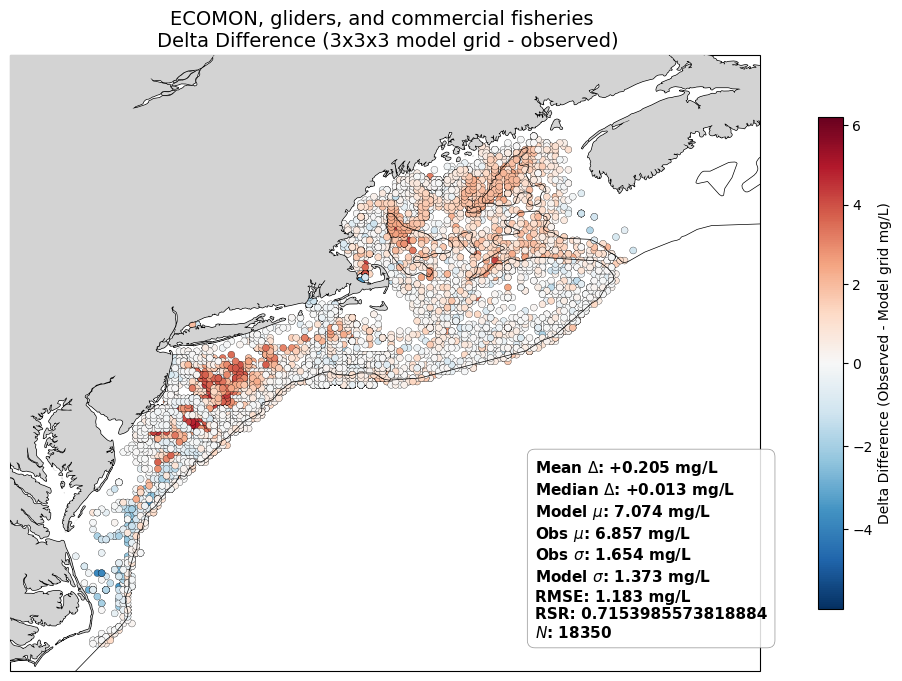

In [29]:
import matplotlib.colors as mcolors

def map_oxygen_delta_difference(csv_file, title):
    final=pd.read_csv(csv_file)
    bathym = cfeature.NaturalEarthFeature(name='bathymetry_K_200', scale='10m', category='physical')
    bathym = unary_union(list(bathym.geometries()))

    fig = plt.figure(figsize=(15, 8)) #set figure size
    map_projection = cartopy.crs.PlateCarree() #set map projection
    ax = plt.axes(projection=map_projection) #link projection to axes
    sc=ax.scatter(final['matched_lon'].astype(float), final['matched_lat'].astype(float), c=final['delta_difference_grid'], cmap='RdBu_r', s=25, edgecolors='black', linewidths=0.2, transform=cartopy.crs.PlateCarree())

    cb = plt.colorbar(sc, shrink=0.8, label='Delta Difference (Observed - Model grid mg/L)')

    # Optional: Center the colorbar around 0 if you want to balance over/underestimation
    # import matplotlib.colors as mcolors
    sc.set_norm(mcolors.TwoSlopeNorm(vcenter=0))

    # 5. Add map layers and features
    ax.add_feature(cfeature.COASTLINE, linewidth=1)
    ax.add_feature(cfeature.LAND, zorder=100, facecolor='lightgrey')
    ax.add_geometries(bathym, facecolor='none', edgecolor='black', linewidth=0.5, crs=cartopy.crs.PlateCarree())

    # 6. Set map spatial limits (Mid-Atlantic Bight / New England shelf)
    ax.set_extent([-77, -63, 34.5, 46])

    # 7. Add text decoration
    ax.set_title(title, fontsize=14)

    #8. Add text to display mean average
    # 1. Calculate the stats cleanly 
    mean_delta = final['delta_difference_grid'].mean()
    median_delta = final['delta_difference_grid'].median()  
    total_pts = len(final['delta_difference_grid'].dropna())
    global_mean = final['cube_mean'].mean()
    obs_mean=df['dissolved_oxygen'].mean()
    global_variance = (df['cube_std']**2).mean() + df['cube_mean'].var()
    global_std = np.sqrt(global_variance)
    global_rmse = np.sqrt((final['delta_difference_grid'] ** 2).mean())
    obs_std = final['dissolved_oxygen'].std()

    # 2. Format the display string 
    text_str = (
        f"Mean $\Delta$: {mean_delta:+.3f} mg/L\n"
        f"Median $\Delta$: {median_delta:+.3f} mg/L\n"
        f"Model $\mu$: {global_mean:.3f} mg/L\n"
        f"Obs $\mu$: {obs_mean:.3f} mg/L\n"
        f"Obs $\sigma$: {obs_std:.3f} mg/L\n"
        f"Model $\sigma$: {global_std:.3f} mg/L\n"
        f"RMSE: {global_rmse:.3f} mg/L\n"
        f"RSR: {global_rmse / obs_std}\n"
        f"$N$: {total_pts}"
    )

    # 3. Define the bounding box style (semi-transparent white block)
    box_style = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.85, edgecolor='gray', linewidth=0.5)

    # 4. Place the text box in the lower-right quadrant of the axes view
    ax.text(
        0.7, 0.05,                   # Coordinates (x=97% right, y=5% up from bottom)
        text_str, 
        transform=ax.transAxes,       # Lock placement to screen space
        fontsize=11, 
        fontweight='bold',
        va='bottom', 
        ha='left', 
        bbox=box_style,
        zorder=105                    # Sits cleanly on top of gray landmasses
    )
    # =====================================================================
    plt.show()
map_oxygen_delta_difference(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\CONCAT_MOM6_3x3x3_comparison.csv", 'ECOMON, gliders, and commercial fisheries \n Delta Difference (3x3x3 model grid - observed)')

start breaking down by year, season
break down delta differences by region

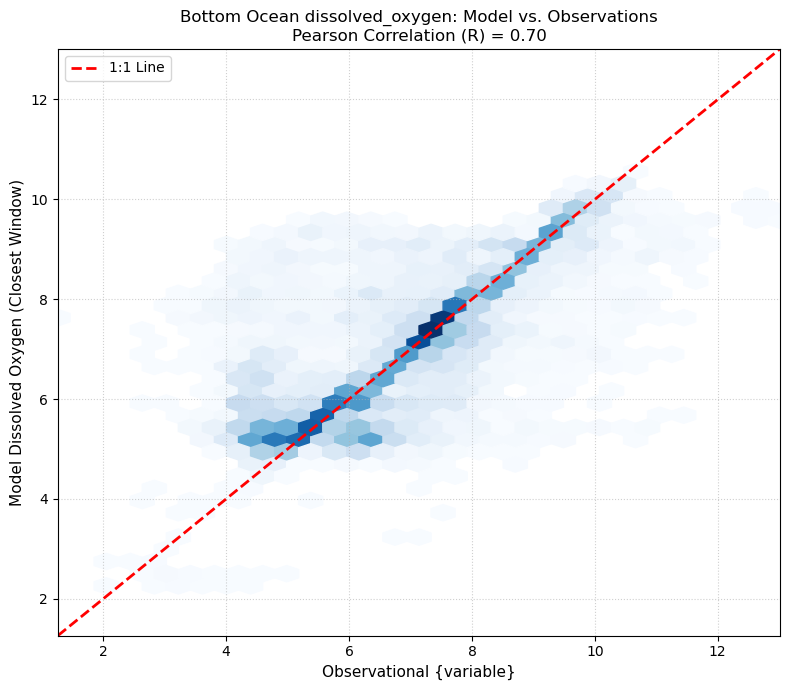

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.colors as mcolors

def plot_model_vs_obs(df, variable):
    # Drop NaNs to ensure clean plotting
    plot_df = df.dropna(subset=[variable, 'closest_model_val']).copy()
    
    x_data = plot_df[variable]
    y_data = plot_df['closest_model_val']
    
    plt.figure(figsize=(8, 7))
    
    # 1. Core Matplotlib scatter plot
    # s=20 sets point size, alpha=0.5 handles overlapping data points beautifully
    plt.hexbin(x_data, y_data, gridsize=30, cmap='Blues', mincnt=1)
    
    # 2. Dynamic 1:1 Line of Perfect Agreement
    min_val = min(x_data.min(), y_data.min())
    max_val = max(x_data.max(), y_data.max())
    plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='1:1 Line')
    
    # 3. Calculate Pearson Correlation (R)
    r_val = x_data.corr(y_data)
    
    # 4. Formatting
    plt.title(f"Bottom Ocean {variable}: Model vs. Observations\nPearson Correlation (R) = {r_val:.2f}", fontsize=12)
    plt.xlabel("Observational {variable}", fontsize=11)
    plt.ylabel("Model Dissolved Oxygen (Closest Window)", fontsize=11)
    
    plt.xlim(min_val, max_val)
    plt.ylim(min_val, max_val)
    plt.legend(loc='upper left')
    plt.grid(True, linestyle=':', alpha=0.6)
    
    plt.tight_layout()
    plt.show()

# Call the function
plot_model_vs_obs(final, 'dissolved_oxygen')

In [22]:
df=pd.read_excel(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\Fishbot_Hypoxia.xlsx")
df=df.dropna(subset=['dissolved_oxygen'])
providers_to_exclude = ['ECOMON']


df = df[~df['data_provider'].isin(providers_to_exclude)]
df.to_csv(processed_data / 'Fishbot_removed_ECOMON.csv')

<>:41: SyntaxWarning: invalid escape sequence '\D'
<>:42: SyntaxWarning: invalid escape sequence '\D'
<>:43: SyntaxWarning: invalid escape sequence '\m'
<>:44: SyntaxWarning: invalid escape sequence '\m'
<>:45: SyntaxWarning: invalid escape sequence '\s'
<>:46: SyntaxWarning: invalid escape sequence '\s'
<>:41: SyntaxWarning: invalid escape sequence '\D'
<>:42: SyntaxWarning: invalid escape sequence '\D'
<>:43: SyntaxWarning: invalid escape sequence '\m'
<>:44: SyntaxWarning: invalid escape sequence '\m'
<>:45: SyntaxWarning: invalid escape sequence '\s'
<>:46: SyntaxWarning: invalid escape sequence '\s'
C:\Users\edmund.gable\AppData\Local\Temp\ipykernel_15032\990316405.py:41: SyntaxWarning: invalid escape sequence '\D'
  f"Mean $\Delta$: {mean_delta:+.3f} mg/L\n"
C:\Users\edmund.gable\AppData\Local\Temp\ipykernel_15032\990316405.py:42: SyntaxWarning: invalid escape sequence '\D'
  f"Median $\Delta$: {median_delta:+.3f} mg/L\n"
C:\Users\edmund.gable\AppData\Local\Temp\ipykernel_15032\9

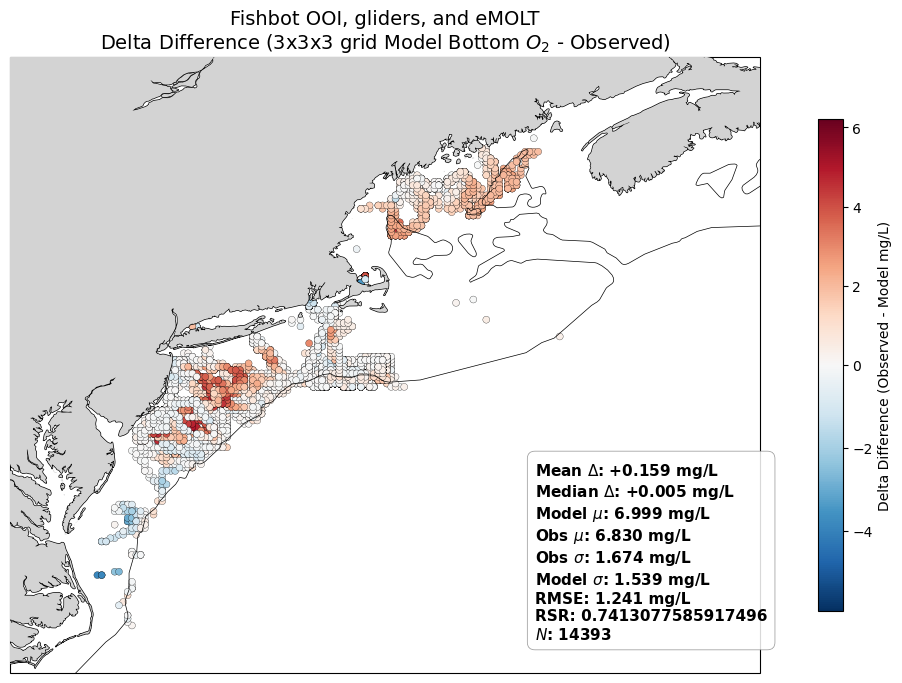

In [19]:
final=pd.read_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\Fishbot_MOM6_3x3x3_comparison.csv")
bathym = cfeature.NaturalEarthFeature(name='bathymetry_K_200', scale='10m', category='physical')
bathym = unary_union(list(bathym.geometries()))

fig = plt.figure(figsize=(15, 8)) #set figure size
map_projection = cartopy.crs.PlateCarree() #set map projection
ax = plt.axes(projection=map_projection) #link projection to axes
sc=ax.scatter(final['matched_lon'].astype(float), final['matched_lat'].astype(float), c=final['delta_difference_grid'], cmap='RdBu_r', s=25, edgecolors='black', linewidths=0.2, transform=cartopy.crs.PlateCarree())

cb = plt.colorbar(sc, shrink=0.8, label='Delta Difference (Observed - Model mg/L)')

# Optional: Center the colorbar around 0 if you want to balance over/underestimation
# import matplotlib.colors as mcolors
sc.set_norm(mcolors.TwoSlopeNorm(vcenter=0))

# 5. Add map layers and features
ax.add_feature(cfeature.COASTLINE, linewidth=1)
ax.add_feature(cfeature.LAND, zorder=100, facecolor='lightgrey')
ax.add_geometries(bathym, facecolor='none', edgecolor='black', linewidth=0.5, crs=cartopy.crs.PlateCarree())

# 6. Set map spatial limits (Mid-Atlantic Bight / New England shelf)
ax.set_extent([-77, -63, 34.5, 46])

# 7. Add text decoration
ax.set_title('Fishbot OOI, gliders, and eMOLT\nDelta Difference (3x3x3 grid Model Bottom $O_2$ - Observed)', fontsize=14)

#8. Add text to display mean average
# 1. Calculate the stats cleanly 
mean_delta = final['delta_difference_grid'].mean()
median_delta = final['delta_difference_grid'].median()  
total_pts = len(final['delta_difference_grid'].dropna())
global_mean = final['cube_mean'].mean()
obs_mean=final['dissolved_oxygen'].mean()
global_variance = (final['cube_std']**2).mean() + final['cube_mean'].var()
global_std = np.sqrt(global_variance)
global_rmse = np.sqrt((final['delta_difference_grid'] ** 2).mean())
obs_std = final['dissolved_oxygen'].std()    

# 2. Format the display string 
text_str = (
    f"Mean $\Delta$: {mean_delta:+.3f} mg/L\n"
    f"Median $\Delta$: {median_delta:+.3f} mg/L\n"
    f"Model $\mu$: {global_mean:.3f} mg/L\n"
    f"Obs $\mu$: {obs_mean:.3f} mg/L\n"
    f"Obs $\sigma$: {obs_std:.3f} mg/L\n"
    f"Model $\sigma$: {global_std:.3f} mg/L\n"
    f"RMSE: {global_rmse:.3f} mg/L\n"
    f"RSR: {global_rmse / obs_std}\n"
    f"$N$: {total_pts}"
)

# 3. Define the bounding box style (semi-transparent white block)
box_style = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.85, edgecolor='gray', linewidth=0.5)

# 4. Place the text box in the lower-right quadrant of the axes view
ax.text(
    0.7, 0.05,                   # Coordinates (x=97% right, y=5% up from bottom)
    text_str, 
    transform=ax.transAxes,       # Lock placement to screen space
    fontsize=11, 
    fontweight='bold',
    va='bottom', 
    ha='left', 
    bbox=box_style,
    zorder=105                    # Sits cleanly on top of gray landmasses
)
# =====================================================================
plt.show()

<>:156: SyntaxWarning: invalid escape sequence '\D'
<>:157: SyntaxWarning: invalid escape sequence '\D'
<>:158: SyntaxWarning: invalid escape sequence '\m'
<>:159: SyntaxWarning: invalid escape sequence '\m'
<>:160: SyntaxWarning: invalid escape sequence '\s'
<>:161: SyntaxWarning: invalid escape sequence '\s'
<>:156: SyntaxWarning: invalid escape sequence '\D'
<>:157: SyntaxWarning: invalid escape sequence '\D'
<>:158: SyntaxWarning: invalid escape sequence '\m'
<>:159: SyntaxWarning: invalid escape sequence '\m'
<>:160: SyntaxWarning: invalid escape sequence '\s'
<>:161: SyntaxWarning: invalid escape sequence '\s'
C:\Users\edmund.gable\AppData\Local\Temp\ipykernel_18024\988890405.py:156: SyntaxWarning: invalid escape sequence '\D'
  f"Mean $\Delta$: {mean_delta:+.3f} mg/L\n"
C:\Users\edmund.gable\AppData\Local\Temp\ipykernel_18024\988890405.py:157: SyntaxWarning: invalid escape sequence '\D'
  f"Median $\Delta$: {median_delta:+.3f} mg/L\n"
C:\Users\edmund.gable\AppData\Local\Temp\ipy

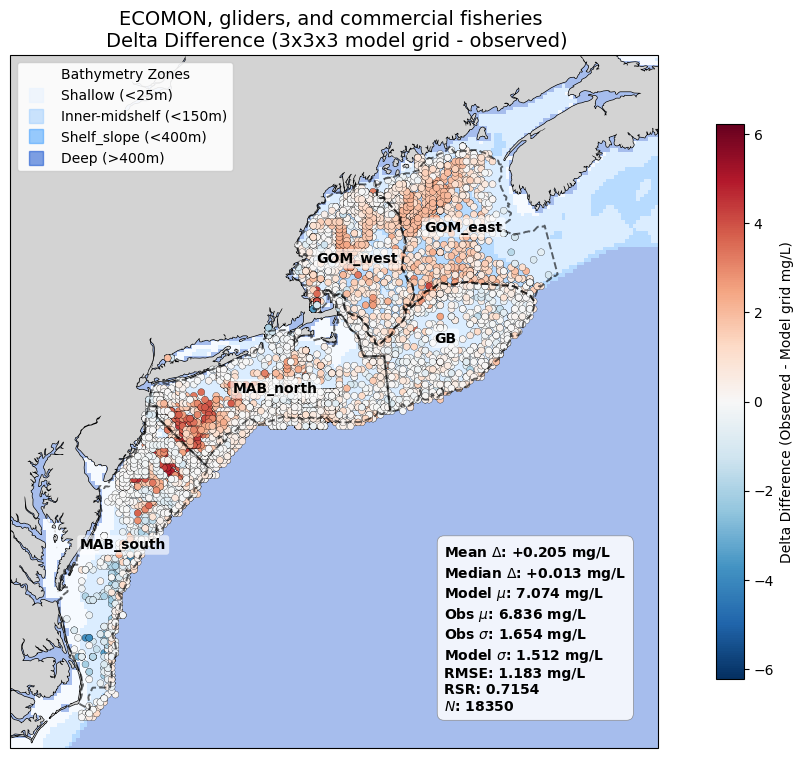

In [55]:
import numpy as np
import cartopy.crs as ccrs          # ccrs handles projections
import cartopy.feature as cfeature  # cfeature handles land, ocean, coastlines
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import pandas as pd
import geopandas as gpd
import xarray as xr
from shapely.ops import unary_union

def map_oxygen_delta_difference(csv_file, bathymetry_nc_path, title):
    # 1. Load delta data and geospatial shapes
    final = pd.read_csv(csv_file)
    
    # Load shapefile (already known to be in EPSG:4326 via your snippet)
    shapefile = gpd.read_file('https://github.com/hsynan/READ-EDAB-Synan_hydrographic_climatologies/raw/refs/heads/main/data/shapefiles/NES_5REGIONS.zip')
    if shapefile.crs is None:
        shapefile.set_crs("epsg:4326", inplace=True)
    elif shapefile.crs != "epsg:4326":
        shapefile = shapefile.to_crs("epsg:4326")

    # Load MOM6 static depth / bathymetry
    # MOM6 files usually use 'lonh'/'lath' or 'geolon'/'geolat' for static metrics
    # and the target depth name given in your variable is 'deptho'
    ds_bathym = xr.open_dataset(bathymetry_nc_path)
    
    # Setup base figure
    fig = plt.figure(figsize=(15, 9))
    map_projection = ccrs.PlateCarree()
    ax = plt.axes(projection=map_projection)

    # 2. Dynamic Symmetric Colorbar Normalization (Centered perfectly at 0)
    max_dev = max(abs(final['delta_difference_grid'].min()), abs(final['delta_difference_grid'].max()))
    div_norm = mcolors.TwoSlopeNorm(vmin=-max_dev, vcenter=0.0, vmax=max_dev)

    # 3. Scatter Plot of Point Observations vs Grid Delta
    sc = ax.scatter(
        final['matched_lon'].astype(float), 
        final['matched_lat'].astype(float), 
        c=final['delta_difference_grid'], 
        cmap='RdBu_r', 
        norm=div_norm,
        s=25, 
        edgecolors='black', 
        linewidths=0.2, 
        transform=map_projection,
        zorder=3
    )

    cb = plt.colorbar(sc, shrink=0.8, label='Delta Difference (Observed - Model grid mg/L)')

    # 4. OVERLAY: Bathymetry Contour Lines from MOM6 NetCDF
    # Dynamically extract horizontal dimensions depending on naming in your .nc file
    lon_var = 'lonh' if 'lonh' in ds_bathym.variables else ('lon' if 'lon' in ds_bathym.variables else 'xh')
    lat_var = 'lath' if 'lath' in ds_bathym.variables else ('lat' if 'lat' in ds_bathym.variables else 'yh')
    
   
    # Custom legend for Discrete Depth Zones
    depth_data = ds_bathym['deptho'].values
    condlist = [
        depth_data < 25,
        (depth_data >= 25) & (depth_data < 150),
        (depth_data >= 150) & (depth_data < 400),
        depth_data >= 400
    ]
    choicelist = [0, 1, 2, 3]
    binned_depth = np.select(condlist, choicelist, default=3)
    cmap_depth = mcolors.ListedColormap(['#e6f2ff', '#99ccff', '#3399ff', '#0044cc'])


    depth_labels = ['Shallow (<25m)', 'Inner-midshelf (<150m)', 'Shelf_slope (<400m)', 'Deep (>400m)']
    patches = [plt.plot([],[], marker="s", ms=10, ls="", color=cmap_depth(i), alpha=0.5, label=depth_labels[i])[0] for i in range(4)]
    depth_legend = ax.legend(handles=patches, loc='lower left', title="Bathymetry Zones", fontsize=10, framealpha=0.9)
    #ax.add_artist(depth_legend) # Keeps this legend 
    # Generate contour lines
    bathym_mesh = ax.pcolormesh(
        ds_bathym[lon_var], ds_bathym[lat_var], binned_depth,
        cmap=cmap_depth, 
        shading='auto',
        alpha=0.35,          
        transform=map_projection,
        zorder=1
    )
    bathym_mesh.set_clip_path(ax.patch)

    # Custom legend for Discrete Depth Zones
    depth_labels = ['Shallow (<25m)', 'Inner-midshelf (<150m)', 'Shelf_slope (<400m)', 'Deep (>400m)']
    patches = [plt.plot([],[], marker="s", ms=10, ls="", color=cmap_depth(i), alpha=0.5, label=depth_labels[i])[0] for i in range(4)]
    depth_legend = ax.legend(handles=patches, loc='upper left', title="Bathymetry Zones", fontsize=10, framealpha=0.9)
    #ax.add_artist(depth_legend) # Keeps this legend 
    # FORCE THE GRID TO CLIP EXACTLY TO THE PLOT BOUNDARIES
    bathym_mesh.set_clip_path(ax.patch)

    # 5. OVERLAY: Regional Shapefile Boundaries & Text Labels
    # Draw regional outlines
    shapefile.geometry.boundary.plot(
        ax=ax, 
        color='black', 
        linewidth=1.4, 
        linestyle='--', 
        alpha=0.6,
        transform=map_projection,
        zorder=10
    )

    # Define dictionary maps matching your shapefile index/id rows
    region_names = {
        0: "MAB_south",
        1: "MAB_north",
        2: "GB",
        3: "GOM_west",
        4: "GOM_east"
    }

    # Iterate through shapes to project their names cleanly on the center of each polygon
    for idx, row in shapefile.iterrows():
        # Get region name safely from index mapping
        name = region_names.get(idx, f"Region {idx}")
        
        # Calculate polygon center centroid for clean labeling text
        centroid = row.geometry.centroid
        
        ax.text(
            centroid.x, centroid.y, name,
            color='black', 
            fontsize=10, 
            fontweight='bold',
            ha='center', 
            va='center',
            transform=map_projection,
            bbox=dict(facecolor='white', alpha=0.6, edgecolor='none', boxstyle='round,pad=0.2'),
            zorder=11
        )

    # 6. Map features and basemaps
    ax.add_feature(cfeature.COASTLINE, linewidth=1)
    ax.add_feature(cfeature.LAND, zorder=2, facecolor='lightgrey')
    
    # Set explicit spatial scope frame
    ax.set_extent([-77, -63, 34.5, 46], crs=ccrs.PlateCarree())
    ax.set_title(title, fontsize=14)

    # 7. Descriptive Stats Block Placement
    mean_delta = final['delta_difference_grid'].mean()
    median_delta = final['delta_difference_grid'].median()  
    total_pts = len(final['delta_difference_grid'].dropna())
    global_mean = final['cube_mean'].mean()
    obs_mean = final['dissolved_oxygen'].mean()   # Fixed: 'df' variable mismatch to 'final'
    obs_std = final['dissolved_oxygen'].std()     # Fixed: 'df' variable mismatch to 'final'
    
    global_variance = (final['cube_std']**2).mean() + final['cube_mean'].var()  # Fixed: 'df' variable mismatch to 'final'
    global_std = np.sqrt(global_variance)
    global_rmse = np.sqrt((final['delta_difference_grid'] ** 2).mean())

    text_str = (
        f"Mean $\Delta$: {mean_delta:+.3f} mg/L\n"
        f"Median $\Delta$: {median_delta:+.3f} mg/L\n"
        f"Model $\mu$: {global_mean:.3f} mg/L\n"
        f"Obs $\mu$: {obs_mean:.3f} mg/L\n"
        f"Obs $\sigma$: {obs_std:.3f} mg/L\n"
        f"Model $\sigma$: {global_std:.3f} mg/L\n"
        f"RMSE: {global_rmse:.3f} mg/L\n"
        f"RSR: {(global_rmse / obs_std):.4f}\n"
        f"$N$: {total_pts}"
    )

    box_style = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.85, edgecolor='gray', linewidth=0.5)
    ax.text(
        0.67, 0.05, 
        text_str, 
        transform=ax.transAxes, 
        fontsize=10, 
        fontweight='bold',
        va='bottom', 
        ha='left', 
        bbox=box_style,
        zorder=105 
    )

    plt.show()

# Execution Syntax
csv_path = r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\CONCAT_MOM6_3x3x3_comparison.csv"
bathymetry_path = r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Bathymetry\MOM6_hindcast_ocean_static_deptho.nc"

map_oxygen_delta_difference(csv_path, bathymetry_path, 'ECOMON, gliders, and commercial fisheries \n Delta Difference (3x3x3 model grid - observed)')

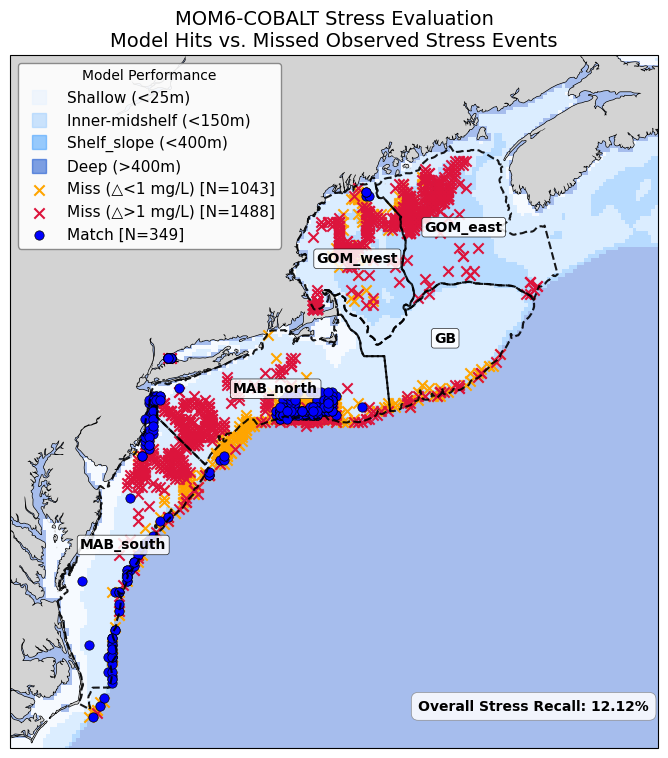

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd
import xarray as xr

def map_stress_advanced_evaluation(csv_file, bathymetry_nc_path, title):
    # 1. Load data and geospatial shapes
    final = pd.read_csv(csv_file)
    
    shapefile = gpd.read_file('https://github.com/hsynan/READ-EDAB-Synan_hydrographic_climatologies/raw/refs/heads/main/data/shapefiles/NES_5REGIONS.zip')
    if shapefile.crs is None:
        shapefile.set_crs("epsg:4326", inplace=True)
    elif shapefile.crs != "epsg:4326":
        shapefile = shapefile.to_crs("epsg:4326")

    ds_bathym = xr.open_dataset(bathymetry_nc_path)
    
    # 2. Crop Bathymetry Grid to Map Extent
    lon_var = 'lonh' if 'lonh' in ds_bathym.variables else ('lon' if 'lon' in ds_bathym.variables else 'xh')
    lat_var = 'lath' if 'lath' in ds_bathym.variables else ('lat' if 'lat' in ds_bathym.variables else 'yh')
    ds_bathym = ds_bathym.sel({lon_var: slice(-78, -62), lat_var: slice(34, 47)})

    # 3. CONVERT CONTINUOUS BATHYMETRY INTO FOUR DISCRETE BINS
    # 0: Shallow, 1: Inner-midshelf, 2: Shelf_slope, 3: Deep
    depth_data = ds_bathym['deptho'].values
    condlist = [
        depth_data < 25,
        (depth_data >= 25) & (depth_data < 150),
        (depth_data >= 150) & (depth_data < 400),
        depth_data >= 400
    ]
    choicelist = [0, 1, 2, 3]
    binned_depth = np.select(condlist, choicelist, default=3)

    # 4. CATEGORIZE ERROR POINTS FOR ACTUAL STRESSED OBSERVATIONS
    stressed_events = final[final['DO_status'] != 'Oxygenated'].copy()
    if len(stressed_events) == 0:
        print("No stressed events found in the dataset to plot.")
        return

    # Calculate absolute error for misses
    stressed_events['abs_error'] = stressed_events['delta_difference_grid'].abs()

    # Split into 3 custom point categories
    matches = stressed_events[stressed_events['model_DO_status'] != 'Oxygenated']
    misses = stressed_events[stressed_events['model_DO_status'] == 'Oxygenated']
    
    miss_low_error = misses[misses['abs_error'] <= 1.0]
    miss_high_error = misses[misses['abs_error'] > 1.0]

    # 5. SETUP FIGURE & BASES
    fig = plt.figure(figsize=(15, 9))
    map_projection = ccrs.PlateCarree()
    ax = plt.axes(projection=map_projection)

    # 6. PLOT DISCRETE BATHYMETRY GRID BACKGROUND
    # Use a specific 4-color listing from light to dark blue
    cmap_depth = mcolors.ListedColormap(['#e6f2ff', '#99ccff', '#3399ff', '#0044cc'])
    
    bathym_mesh = ax.pcolormesh(
        ds_bathym[lon_var], ds_bathym[lat_var], binned_depth,
        cmap=cmap_depth, 
        shading='auto',
        alpha=0.35,          
        transform=map_projection,
        zorder=1
    )
    bathym_mesh.set_clip_path(ax.patch)

    # Custom legend for Discrete Depth Zones
    depth_labels = ['Shallow (<25m)', 'Inner-midshelf (<150m)', 'Shelf_slope (<400m)', 'Deep (>400m)']
    patches = [plt.plot([],[], marker="s", ms=10, ls="", color=cmap_depth(i), alpha=0.5, label=depth_labels[i])[0] for i in range(4)]
    depth_legend = ax.legend(handles=patches, loc='lower left', title="Bathymetry Zones", fontsize=10, framealpha=0.9)
    #ax.add_artist(depth_legend) # Keeps this legend active when adding the point legend

    # 7. PLOT DYNAMIC THREE-TIER POINT METRICS
    # Tier 1: Missed stress, but minor error <= 1 mg/L (Light Blue 'x')
    sc_miss_low = ax.scatter(
        miss_low_error['matched_lon'].astype(float), miss_low_error['matched_lat'].astype(float),
        color='orange', marker='x', s=55, linewidths=1.5,
        label=f"Miss (△<1 mg/L) [N={len(miss_low_error)}]",
        transform=map_projection, zorder=5
    )
    
    # Tier 2: Missed stress, major error > 1 mg/L (Red 'x')
    sc_miss_high = ax.scatter(
        miss_high_error['matched_lon'].astype(float), miss_high_error['matched_lat'].astype(float),
        color='crimson', marker='x', s=55, linewidths=1.5,
        label=f"Miss (△>1 mg/L) [N={len(miss_high_error)}]",
        transform=map_projection, zorder=6
    )

    # Tier 3: Match / Correctly Predicted Stress (Blue Circle)
    sc_match = ax.scatter(
        matches['matched_lon'].astype(float), matches['matched_lat'].astype(float),
        color='blue', marker='o', s=45, edgecolors='black', linewidths=0.5,
        label=f"Match [N={len(matches)}]",
        transform=map_projection, zorder=7
    )

    # Add Point Category Legend
    ax.legend(loc='upper left', title="Model Performance", fontsize=11, framealpha=0.9, facecolor='white', edgecolor='gray')

    # 8. OVERLAY: Regional Shapefile Boundaries
    shapefile.geometry.boundary.plot(
        ax=ax, color='black', linewidth=1.5, linestyle='--', alpha=0.9,
        transform=map_projection, zorder=10
    )

    region_names = {0: "MAB_south", 1: "MAB_north", 2: "GB", 3: "GOM_west", 4: "GOM_east"}
    for idx, row in shapefile.iterrows():
        name = region_names.get(idx, f"Region {idx}")
        centroid = row.geometry.centroid
        ax.text(
            centroid.x, centroid.y, name,
            color='black', fontsize=10, fontweight='bold',
            ha='center', va='center', transform=map_projection,
            bbox=dict(facecolor='white', alpha=0.85, edgecolor='black', linewidth=0.5, boxstyle='round,pad=0.2'),
            zorder=11
        )

    # 9. Map framing assets
    ax.add_feature(cfeature.COASTLINE, linewidth=1)
    ax.add_feature(cfeature.LAND, zorder=2, facecolor='lightgrey')
    ax.set_extent([-77, -63, 34.5, 46], crs=map_projection)
    ax.set_title(title, fontsize=14)

    # 10. Performance Metric Display Block
    total_stress = len(stressed_events)
    recall = (len(matches) / total_stress) * 100 if total_stress > 0 else 0
    
    text_str = (
        f"Overall Stress Recall: {recall:.2f}%"
    )
    box_style = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.85, edgecolor='gray', linewidth=0.5)
    ax.text(
        0.63, 0.05, text_str, transform=ax.transAxes, 
        fontsize=10, fontweight='bold', va='bottom', ha='left', 
        bbox=box_style, zorder=105 
    )

    plt.show()


csv_path = r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\CONCAT_MOM6_3x3x3_comparison.csv"
bathymetry_path = r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Bathymetry\MOM6_hindcast_ocean_static_deptho.nc"

map_stress_advanced_evaluation(csv_path, bathymetry_path, 'MOM6-COBALT Stress Evaluation\nModel Hits vs. Missed Observed Stress Events')
# Execution Call syntax remains exactly the same

In [ ]:
final=
plot_model_vs_obs(final, 'dissolved_oxygen')